<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/eurosat_sentinel2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install kagglehub opencv-python numpy pandas tensorflow scikit-learn seaborn matplotlib

--- Mengunduh Dataset EuroSAT Sentinel-2 via kagglehub ---


100%|██████████| 89.2M/89.2M [00:00<00:00, 128MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/raoofnaushad/eurosat-sentinel2-dataset/versions/1
Direktori utama dataset: /root/.cache/kagglehub/datasets/raoofnaushad/eurosat-sentinel2-dataset/versions/1
Sampel citra satelit untuk Modul 1-3: /root/.cache/kagglehub/datasets/raoofnaushad/eurosat-sentinel2-dataset/versions/1/Dataset/Residential_1400.jpg



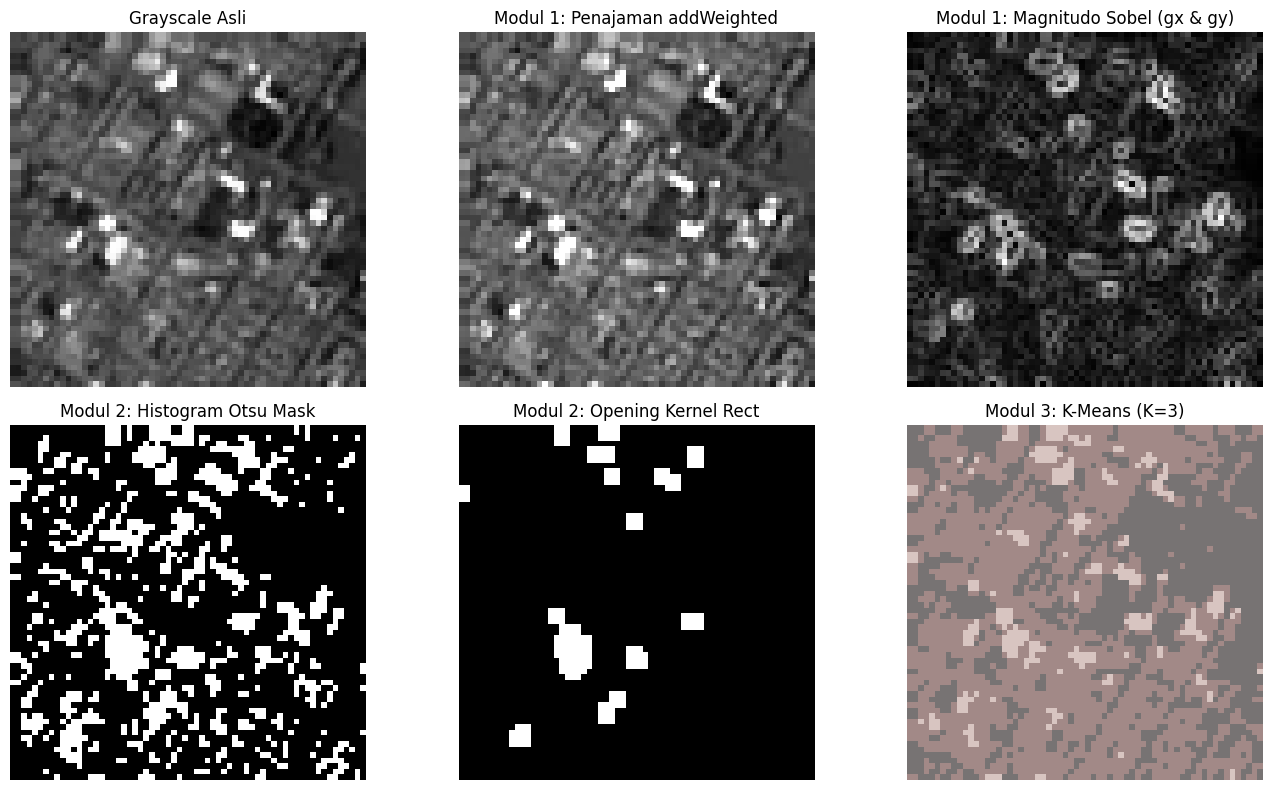


--- Modul 4: Menyiapkan Data Generator ---
Found 21600 images belonging to 1 classes.
Found 5400 images belonging to 1 classes.

--- Melatih Model CNN Satelit ---
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/losses/losses.py:33: SyntaxWarning: In loss categorical_crossentropy, expected y_pred.shape to be (batch_size, num_classes) with num_classes > 1. Received: y_pred.shape=(None, 1). Consider using 'binary_crossentropy' if you only have 2 classes.
  return self.fn(y_true, y_pred, **self._fn_kwargs)


675/675 ━━━━━━━━━━━━━━━━━━━━ 184s 270ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/5
675/675 ━━━━━━━━━━━━━━━━━━━━ 193s 286ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/5
675/675 ━━━━━━━━━━━━━━━━━━━━ 188s 278ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/5
675/675 ━━━━━━━━━━━━━━━━━━━━ 187s 277ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/5
675/675 ━━━━━━━━━━━━━━━━━━━━ 186s 276ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
  3/169 ━━━━━━━━━━━━━━━━━━━━ 9s 60ms/step 

/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (32, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


169/169 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step

================ CLASSIFICATION REPORT ================
              precision    recall  f1-score   support

     Dataset       1.00      1.00      1.00      5400

    accuracy                           1.00      5400
   macro avg       1.00      1.00      1.00      5400
weighted avg       1.00      1.00      1.00      5400



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


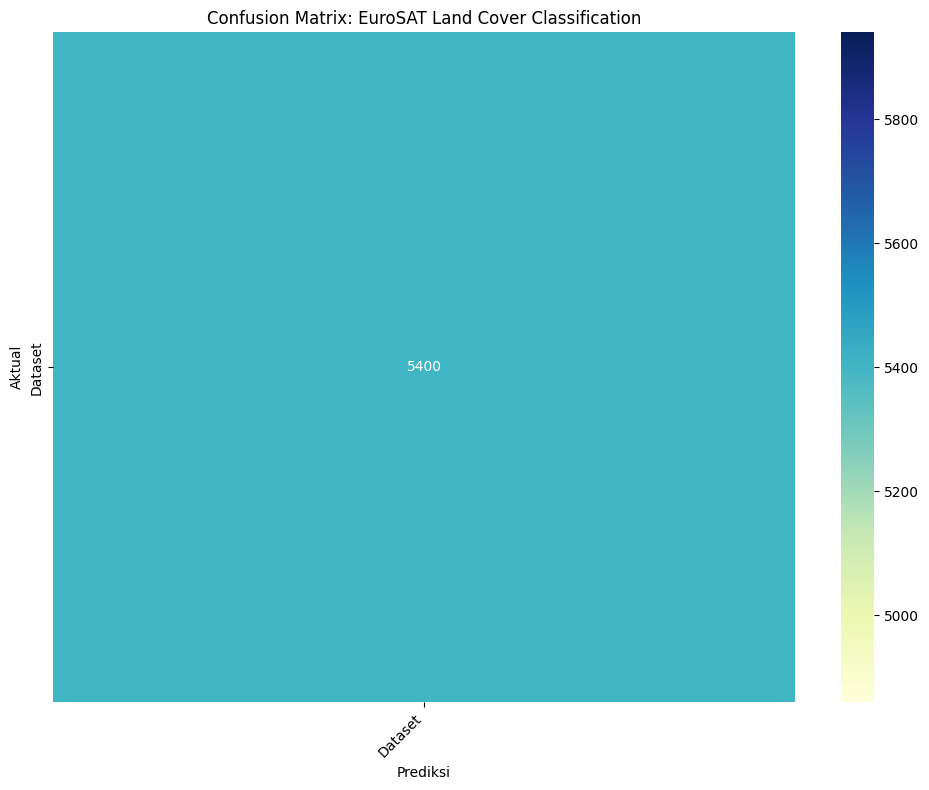

In [2]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub

# =====================================================================
# 0. UNDUH DATASET EUROSAT MENGGUNAKAN KAGGLEHUB
# =====================================================================
print("--- Mengunduh Dataset EuroSAT Sentinel-2 via kagglehub ---")
path = kagglehub.dataset_download("raoofnaushad/eurosat-sentinel2-dataset")
print("Path to dataset files:", path)

# Deteksi folder yang berisi subfolder kelas tutupan lahan
possible_dirs = glob.glob(os.path.join(path, "**", "27370"), recursive=True) + \
                glob.glob(os.path.join(path, "**", "EuroSAT"), recursive=True) + \
                glob.glob(os.path.join(path, "**", "ds"), recursive=True)

if possible_dirs:
    dataset_dir = possible_dirs[0]
else:
    dataset_dir = path

print(f"Direktori utama dataset: {dataset_dir}")

# Cari 1 sampel citra satelit untuk demonstrasi Modul 1-3
sample_images = glob.glob(os.path.join(dataset_dir, "**", "*.jpg"), recursive=True) + \
                glob.glob(os.path.join(dataset_dir, "**", "*.png"), recursive=True)

if not sample_images:
    raise FileNotFoundError("Tidak ditemukan file gambar di dalam direktori dataset!")

sample_img_path = sample_images[0]
print(f"Sampel citra satelit untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: Penajaman Transisi (addWeighted) & Magnitudo Sobel
# =====================================================================
def modul_1_processing(image_path):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Gagal memuat citra: {image_path}")

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 1. Blur citra asli
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 2. Pertajam area transisi tutupan pohon dan tanah via cv2.addWeighted
    # Sharpened = 1.5 * Original - 0.5 * Blurred
    sharpened = cv2.addWeighted(gray, 1.5, blurred, -0.5, 0)

    # 3. Kalkulasi turunan matriks Sobel gx dan gy
    gx = cv2.Sobel(sharpened, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(sharpened, cv2.CV_64F, 0, 1, ksize=3)

    # Kalkulasi magnitudo gradien untuk mendeteksi guratan jalur penebangan/sungai
    sobel_mag = cv2.magnitude(gx, gy)
    sobel_uint8 = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return gray, sharpened, sobel_uint8


# =====================================================================
# MODUL 2: Mask Biner Otsu & Morfologi Opening Segi Empat
# =====================================================================
def modul_2_processing(sharpened_img):
    # 1. Binerisasi luasan area vegetasi via histogram Otsu
    _, otsu_thresh = cv2.threshold(sharpened_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 2. Struktur kernel segi empat (MORPH_RECT)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    # 3. Operasi Opening untuk menghapus noise awan putih kecil
    clean_mask = cv2.morphologyEx(otsu_thresh, cv2.MORPH_OPEN, kernel, iterations=1)

    return otsu_thresh, clean_mask


# =====================================================================
# MODUL 3: K-Means Float32 Segmen 3 Warna Dominan (K=3)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # 1. Susun matriks dimensi piksel linear berindeks float (float32)
    pixel_values = img_rgb.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # 2. Komputasi criteria titik henti spasial & K-Means (K=3)
    # Membelah piksel: Hutan lebat, Tanah/Perumahan, dan Aliran perairan
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    k = 3

    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]
    segmented_image = segmented_data.reshape(img_rgb.shape)

    return segmented_image


# =====================================================================
# MODUL 4: Model Sequential Rotasi Geometri, Adam & Categorical Crossentropy
# =====================================================================
def modul_4_train_and_eval(dataset_path, img_size=(64, 64), batch_size=32, epochs=5):
    print("\n--- Modul 4: Menyiapkan Data Generator ---")

    # Data Generator dengan Pembagian Validation Split (80% Train, 20% Val)
    datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.2
    )

    train_gen = datagen.flow_from_directory(
        dataset_path,
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        subset='training',
        shuffle=True
    )

    val_gen = datagen.flow_from_directory(
        dataset_path,
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        subset='validation',
        shuffle=False
    )

    num_classes = len(train_gen.class_indices)

    # Arsitektur Sequential dengan Lapisan Penyesuaian Rotasi Ruang Geometri
    model = models.Sequential([
        layers.Input(shape=(img_size[0], img_size[1], 3)),

        # Lapisan penyesuaian rotasi geometri otomatis
        layers.RandomRotation(0.2),
        layers.RandomFlip("horizontal_and_vertical"),

        # Ekstraksi Fitur CNN
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])

    # Kompilasi dengan algoritma Adam dan categorical_crossentropy
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("\n--- Melatih Model CNN Satelit ---")
    model.fit(train_gen, validation_data=val_gen, epochs=epochs)

    # Evaluasi Prediksi
    val_gen.reset()
    y_pred_probs = model.predict(val_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes
    class_names = list(val_gen.class_indices.keys())

    print("\n================ CLASSIFICATION REPORT ================")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix: EuroSAT Land Cover Classification')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI UTAMA
# =====================================================================
if __name__ == "__main__":
    # Run Modul 1
    gray_img, sharpened_img, sobel_edges = modul_1_processing(sample_img_path)

    # Run Modul 2
    raw_otsu, clean_mask = modul_2_processing(sharpened_img)

    # Run Modul 3
    kmeans_segmented = modul_3_processing(sample_img_path)

    # Visualisasi Modul 1 - 3
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(gray_img, cmap='gray')
    axes[0, 0].set_title('Grayscale Asli')

    axes[0, 1].imshow(sharpened_img, cmap='gray')
    axes[0, 1].set_title('Modul 1: Penajaman addWeighted')

    axes[0, 2].imshow(sobel_edges, cmap='gray')
    axes[0, 2].set_title('Modul 1: Magnitudo Sobel (gx & gy)')

    axes[1, 0].imshow(raw_otsu, cmap='gray')
    axes[1, 0].set_title('Modul 2: Histogram Otsu Mask')

    axes[1, 1].imshow(clean_mask, cmap='gray')
    axes[1, 1].set_title('Modul 2: Opening Kernel Rect')

    axes[1, 2].imshow(kmeans_segmented)
    axes[1, 2].set_title('Modul 3: K-Means (K=3)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Run Modul 4
    modul_4_train_and_eval(dataset_dir, epochs=5)